Fit window: 10-30 ns (81 bins)
T1 = 6.617 +/- 0.283 ns (approximate 1-sigma uncertainty)
Background = 3.721 counts/bin
Gaussian window: 6-9 ns (13 bins)
Gaussian center = 7.828 ns; sigma = 0.500 ns
Fitted laser counts = 20197.66; emitted counts in decay window = 6940.23
Emission / laser = 0.3436 (-4.64 dB)
Laser / emission = 2.91
This is a detected-count ratio in the selected windows, not incident-laser extinction.
Gaussian FWHM = 1.177 ns


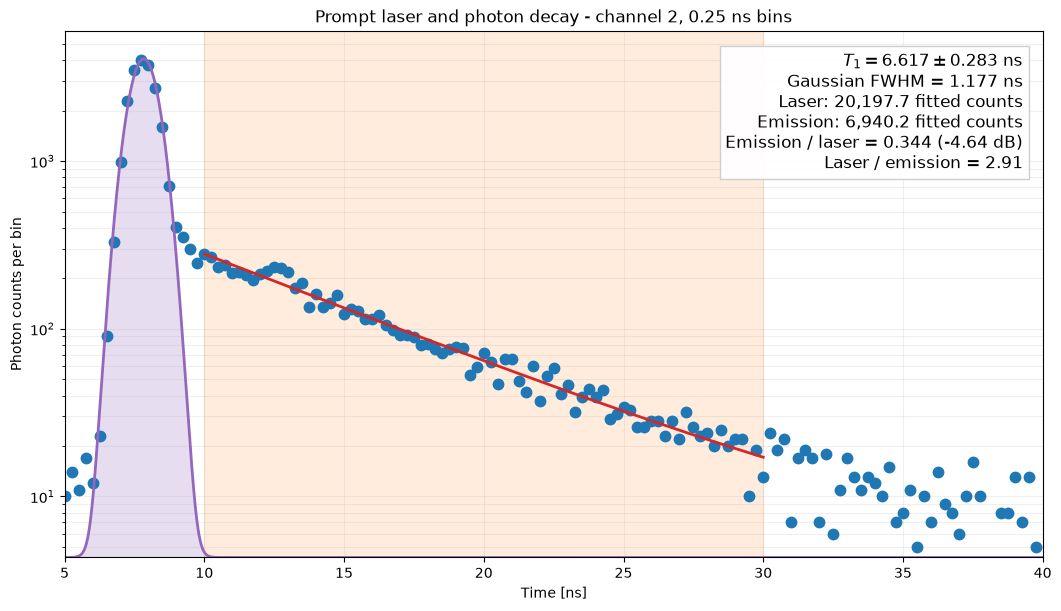

In [2]:
# Plot limits for the first figure (independent of the fit windows).
plot_x_limits_ns = (5.0, 40.0)
# None for the lower limit uses fitted Gaussian baseline y_0;
# None for the upper limit chooses a value above the histogram maximum.
plot_y_limits_counts = (None, None)

# Edit these fit limits (ns), then rerun this cell.
gaussian_fit_start_ns = 6.0
gaussian_fit_end_ns = 9.0
fit_start_ns = 10
fit_end_ns = 30.0

from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.special import xlogy, erf


file_path = Path(r"C:\Users\yy3\qudi\Data\2026\09\2026-09-28\timetaggerlogic\20260928-1601-28_hist_data_trace_zpl_decay_nice.dat")
counts = np.loadtxt(file_path)
header = file_path.read_text()
bin_width_ns = float(re.search(r"^# bin width=(.+)$", header, re.MULTILINE).group(1)) * 1e9
delay_ns = np.arange(counts.size) * bin_width_ns

if not np.isfinite([fit_start_ns, fit_end_ns]).all() or not (
    delay_ns[0] <= fit_start_ns < fit_end_ns <= delay_ns[-1]
):
    raise ValueError(f"Choose 0 <= fit_start_ns < fit_end_ns <= {delay_ns[-1]:g} ns.")
if not np.isfinite(counts).all() or (counts < 0).any():
    raise ValueError("Counts must be finite and nonnegative.")
fit_mask = (delay_ns >= fit_start_ns) & (delay_ns <= fit_end_ns)
x_fit = delay_ns[fit_mask] - fit_start_ns
y_fit = counts[fit_mask]
if y_fit.size < 5 or y_fit.sum() == 0:
    raise ValueError("The fit window must contain at least five bins and nonzero counts.")

# A is the exponential amplitude at the start of the selected window.
# Fit raw counts with Poisson statistics, including zero-count bins.
def decay(t, amplitude, t1_ns, background):
    return amplitude * np.exp(-t / t1_ns) + background

def poisson_residuals(parameters):
    expected = np.maximum(decay(x_fit, *parameters), 1e-12)
    deviance = 2 * (xlogy(y_fit, y_fit / expected) - y_fit + expected)
    return np.sign(expected - y_fit) * np.sqrt(np.maximum(deviance, 0))

background_guess = max(float(np.mean(y_fit[-max(3, y_fit.size // 10):])), 0.1)
initial = [max(float(y_fit.max()) - background_guess, 1),
           (fit_end_ns - fit_start_ns) / 5, background_guess]
fit_result = least_squares(poisson_residuals, initial,
                           bounds=([0, 1e-6, 0], [np.inf, np.inf, np.inf]),
                           x_scale='jac', max_nfev=10000)
if not fit_result.success:
    raise RuntimeError(f"Decay fit failed: {fit_result.message}")
amplitude, t1_ns, background = fit_result.x

# Approximate 1-sigma uncertainty from the Poisson Fisher information.
expected = decay(x_fit, amplitude, t1_ns, background)
exponential = np.exp(-x_fit / t1_ns)
jacobian = np.column_stack((exponential,
    amplitude * exponential * x_fit / t1_ns**2, np.ones_like(x_fit)))
fisher = jacobian.T @ (jacobian / np.maximum(expected[:, None], 1e-12))
if np.linalg.matrix_rank(fisher) < 3:
    raise RuntimeError("This window does not constrain T1; choose a wider decay interval.")
covariance = np.linalg.inv(fisher)
t1_error_ns = np.sqrt(covariance[1, 1])
print(f"Fit window: {fit_start_ns:g}-{fit_end_ns:g} ns ({y_fit.size} bins)")
print(f"T1 = {t1_ns:.3f} +/- {t1_error_ns:.3f} ns (approximate 1-sigma uncertainty)")
print(f"Background = {background:.3f} counts/bin")

# Fit the prompt laser peak independently, using Gaussian + constant background.
# The selected prompt interval should cover the peak without much decay tail.
def gaussian(t, peak, center_ns, sigma_ns, offset):
    return peak * np.exp(-0.5 * ((t - center_ns) / sigma_ns)**2) + offset


def gaussian_signal_counts(peak, center_ns, sigma_ns, start_ns, end_ns, bin_ns):
    """Background-subtracted fitted counts within the specified time interval."""
    z = (np.asarray([start_ns, end_ns]) - center_ns) / (np.sqrt(2) * sigma_ns)
    return float(peak * sigma_ns * np.sqrt(np.pi / 2) * (erf(z[1]) - erf(z[0])) / bin_ns)


def decay_signal_counts(peak, lifetime_ns, start_ns, end_ns, bin_ns):
    """peak is the exponential amplitude at start_ns; exclude background."""
    return float(peak * lifetime_ns * (-np.expm1(-(end_ns - start_ns) / lifetime_ns)) / bin_ns)


if not np.isfinite([gaussian_fit_start_ns, gaussian_fit_end_ns]).all() or not (
    delay_ns[0] <= gaussian_fit_start_ns < gaussian_fit_end_ns <= delay_ns[-1]
):
    raise ValueError("Choose a finite Gaussian fit window within the histogram.")
if gaussian_fit_end_ns > fit_start_ns:
    raise ValueError("Use non-overlapping Gaussian and decay windows to avoid counting the same interval twice.")
gaussian_mask = (delay_ns >= gaussian_fit_start_ns) & (delay_ns <= gaussian_fit_end_ns)
gx, gy = delay_ns[gaussian_mask], counts[gaussian_mask]
if gy.size < 5 or gy.sum() == 0:
    raise ValueError("The Gaussian window must contain at least five bins and nonzero counts.")


def gaussian_poisson_residuals(parameters):
    expected = np.maximum(gaussian(gx, *parameters), 1e-12)
    deviance = 2 * (xlogy(gy, gy / expected) - gy + expected)
    return np.sign(expected - gy) * np.sqrt(np.maximum(deviance, 0))


gaussian_span = gaussian_fit_end_ns - gaussian_fit_start_ns
gaussian_background_guess = max(float(gy.min()), 0.1)
gaussian_initial = [max(float(gy.max()) - gaussian_background_guess, 1),
                    float(gx[np.argmax(gy)]), gaussian_span / 6, gaussian_background_guess]
gaussian_result = least_squares(
    gaussian_poisson_residuals, gaussian_initial,
    bounds=([0, gaussian_fit_start_ns, bin_width_ns / 10, 0],
            [np.inf, gaussian_fit_end_ns, gaussian_span, np.inf]),
    x_scale='jac', max_nfev=10000,
)
if not gaussian_result.success:
    raise RuntimeError(f"Gaussian fit failed: {gaussian_result.message}")
gaussian_peak, gaussian_center_ns, gaussian_sigma_ns, gaussian_background = gaussian_result.x

# Both amplitudes are counts/bin. Integrate signal above its fitted constant
# background and divide by bin width to obtain counts, not counts*ns.
# Use exactly the selected fit intervals; do not extrapolate to t=0 or infinity.
laser_counts = gaussian_signal_counts(
    gaussian_peak, gaussian_center_ns, gaussian_sigma_ns,
    gaussian_fit_start_ns, gaussian_fit_end_ns, bin_width_ns)
emission_counts = decay_signal_counts(amplitude, t1_ns, fit_start_ns, fit_end_ns, bin_width_ns)
if laser_counts <= 0 or emission_counts <= 0:
    raise ValueError("Both fitted signal areas must be positive to calculate suppression.")
suppression_ratio = emission_counts / laser_counts
suppression_db = 10 * np.log10(suppression_ratio)
laser_to_emission_ratio = laser_counts / emission_counts
print(f"Gaussian window: {gaussian_fit_start_ns:g}-{gaussian_fit_end_ns:g} ns ({gy.size} bins)")
print(f"Gaussian center = {gaussian_center_ns:.3f} ns; sigma = {gaussian_sigma_ns:.3f} ns")
print(f"Fitted laser counts = {laser_counts:.2f}; emitted counts in decay window = {emission_counts:.2f}")
print(f"Emission / laser = {suppression_ratio:.4g} ({suppression_db:.2f} dB)")
print(f"Laser / emission = {laser_to_emission_ratio:.4g}")
print("This is a detected-count ratio in the selected windows, not incident-laser extinction.")

fig, ax = plt.subplots(figsize=(10.5, 6), constrained_layout=True)
ax.semilogy(delay_ns, np.where(counts > 0, counts, np.nan), '.', markersize=15, color='tab:blue', label='Photon counts')
ax.axvspan(fit_start_ns, fit_end_ns, color='tab:orange', alpha=0.14,
           label=f'Decay fit window: {fit_start_ns:g}-{fit_end_ns:g} ns')
fit_time = np.linspace(fit_start_ns, fit_end_ns, 500)
ax.plot(fit_time, decay(fit_time - fit_start_ns, *fit_result.x),
        color='tab:red', linewidth=2, label='Exponential + background')
# Display the Gaussian across the full plotted range; fit limits remain unchanged.
plot_start_ns, plot_end_ns = plot_x_limits_ns
if not np.isfinite([plot_start_ns, plot_end_ns]).all() or plot_start_ns >= plot_end_ns:
    raise ValueError("plot_x_limits_ns must contain finite, increasing limits.")
gaussian_time = np.linspace(plot_start_ns, plot_end_ns, 2000)
gaussian_curve = gaussian(gaussian_time, *gaussian_result.x)
gaussian_fwhm_ns = 2 * np.sqrt(2 * np.log(2)) * gaussian_sigma_ns
ax.plot(gaussian_time, gaussian_curve,
        color='tab:purple', linewidth=2, label='Gaussian + background')
# The physical fill baseline is the fitted Gaussian offset, not the plot limit.
y_0 = float(gaussian_background)
y_min, y_max = plot_y_limits_counts
if y_min is None:
    # Zero itself cannot be shown on a log axis. This fallback only controls
    # the visible axis; the fitted baseline and area calculation stay unchanged.
    positive_counts = counts[counts > 0]
    y_min = y_0 if y_0 > 0 else float(positive_counts.min()) / 2
if y_max is None:
    y_max = max(400, float(counts.max()) * 1.5)
if not np.isfinite([y_min, y_max]).all() or not 0 < y_min < y_max:
    raise ValueError("Logarithmic plot y limits must satisfy 0 < lower < upper.")
ax.fill_between(gaussian_time, y_0, gaussian_curve,
                color='tab:purple', alpha=0.22, linewidth=0)
print(f"Gaussian FWHM = {gaussian_fwhm_ns:.3f} ns")
ax.text(0.98, 0.96,
        rf'$T_1 = {t1_ns:.3f} \pm {t1_error_ns:.3f}\ \mathrm{{ns}}$'
        + '\n' + f'Gaussian FWHM = {gaussian_fwhm_ns:.3f} ns'
        + '\n' + f'Laser: {laser_counts:,.1f} fitted counts'
        + '\n' + f'Emission: {emission_counts:,.1f} fitted counts'
        + '\n' + f'Emission / laser = {suppression_ratio:.3g} ({suppression_db:+.2f} dB)'
        + '\n' + f'Laser / emission = {laser_to_emission_ratio:.3g}',
        transform=ax.transAxes, ha='right', va='top', fontsize=12,
        bbox=dict(facecolor='white', edgecolor='0.8', alpha=0.95))
ax.set_xlabel('Time [ns]')
ax.set_ylabel('Photon counts per bin')
ax.set_title(f'Prompt laser and photon decay - channel 2, {bin_width_ns:g} ns bins')
ax.grid(True, which='both', alpha=0.2)
ax.set_xlim(plot_start_ns, plot_end_ns)
ax.set_ylim(y_min, y_max)
# ax.legend(loc='left', fontsize=9)
plt.show()


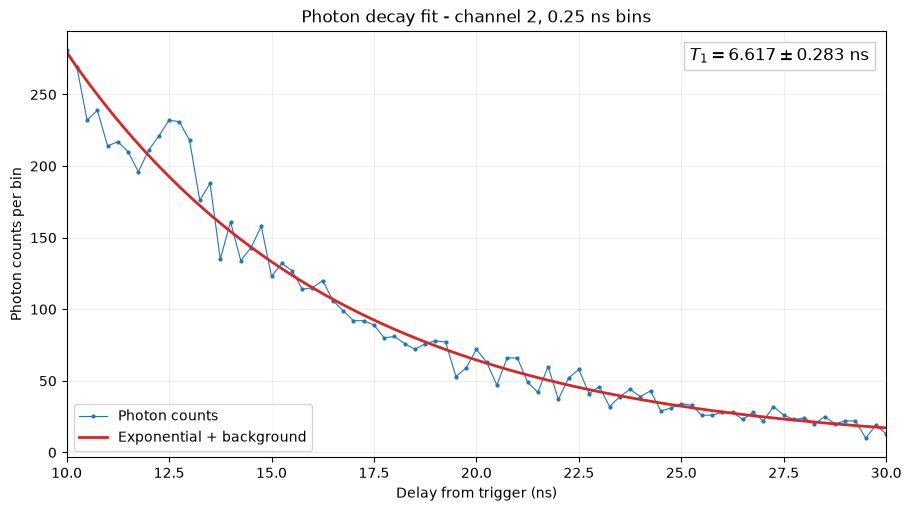

In [3]:
# Run the fit cell above first. Show only the fitted interval on a linear axis.
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.plot(delay_ns[fit_mask], y_fit, '.-', linewidth=0.8, markersize=4,
        color='tab:blue', label='Photon counts')
fit_time = np.linspace(fit_start_ns, fit_end_ns, 500)
ax.plot(fit_time, decay(fit_time - fit_start_ns, *fit_result.x),
        color='tab:red', linewidth=2, label='Exponential + background')
ax.text(0.98, 0.96,
        rf'$T_1 = {t1_ns:.3f} \pm {t1_error_ns:.3f}\ \mathrm{{ns}}$',
        transform=ax.transAxes, ha='right', va='top', fontsize=12,
        bbox=dict(facecolor='white', edgecolor='0.8', alpha=0.95))
ax.set_xlim(fit_start_ns, fit_end_ns)
ax.set_yscale('linear')
ax.set_xlabel('Delay from trigger (ns)')
ax.set_ylabel('Photon counts per bin')
ax.set_title(f'Photon decay fit - channel 2, {bin_width_ns:g} ns bins')
ax.grid(True, alpha=0.2)
ax.legend(loc='lower left')
plt.show()


### Detected laser-to-emission comparison
Edit `gaussian_fit_start_ns` / `gaussian_fit_end_ns` for the prompt peak and
`fit_start_ns` / `fit_end_ns` for the decay. Both fits use Poisson deviance,
including bins with zero counts. The Gaussian is fitted independently; a
window contaminated by fluorescence can bias the inferred laser area.

With bin width $\Delta t$, Gaussian signal $G(t)=H\exp[-(t-\mu)^2/(2\sigma^2)]$
and decay signal $D(t)=A\exp[-(t-t_0)/T_1]$, the background-subtracted counts are

$$N_L=\frac{1}{\Delta t}\int_{g_0}^{g_1}G(t)\,dt,\qquad
N_E=\frac{A T_1}{\Delta t}\left[1-\exp\left(-\frac{t_1-t_0}{T_1}\right)\right].$$

We report $S=N_E/N_L$ and $S_{\rm dB}=10\log_{10}(S)$, as well as the
reciprocal laser/emission ratio. Positive dB means more detected emission than
prompt laser counts; negative dB means prompt laser counts dominate. These
are fitted counts **within the selected intervals**, not the total emitted
photons extrapolated beneath the prompt peak. This is not an optical extinction
measurement: that would require an incident or unsuppressed-laser reference.


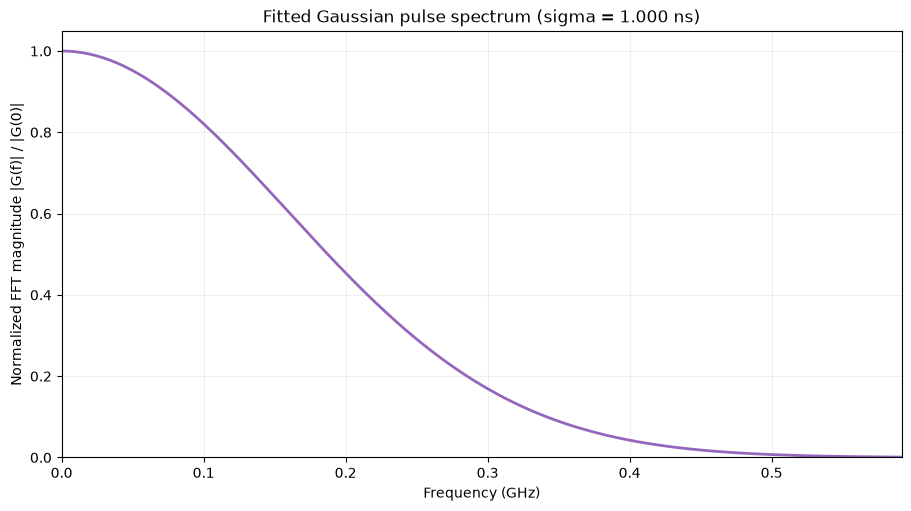

In [5]:
# Run the fit cell first. FFT of the fitted Gaussian signal, excluding background.
# Sample the model over +/-8 sigma so its tails are negligible at the edges.
# This is the spectrum of the photon-count pulse envelope, not the optical field.
gaussian_sigma_ns = 1
fft_dt_ns = gaussian_sigma_ns / 32
fft_time_ns = gaussian_center_ns + np.arange(-256, 256) * fft_dt_ns
fft_pulse = gaussian(fft_time_ns, gaussian_peak, gaussian_center_ns, gaussian_sigma_ns, 0)
# Zero padding gives a smoother frequency grid, not additional measured resolution.
fft_size = 16384
pulse_fft = np.fft.rfft(fft_pulse, n=fft_size) * fft_dt_ns
fft_frequency_ghz = np.fft.rfftfreq(fft_size, d=fft_dt_ns)  # 1/ns = GHz
fft_magnitude = np.abs(pulse_fft) / np.abs(pulse_fft[0])

fft_fig, fft_ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
fft_ax.plot(fft_frequency_ghz, fft_magnitude, color='tab:purple', linewidth=2)
# Show positive frequencies down to a relative magnitude of 0.001.
fft_ax.set_xlim(0, np.sqrt(2 * np.log(1000)) / (2 * np.pi * gaussian_sigma_ns))
fft_ax.set_ylim(0, 1.05)
fft_ax.set_xlabel('Frequency (GHz)')
fft_ax.set_ylabel('Normalized FFT magnitude |G(f)| / |G(0)|')
fft_ax.set_title(f'Fitted Gaussian pulse spectrum (sigma = {gaussian_sigma_ns:.3f} ns)')
fft_ax.grid(True, alpha=0.2)
plt.show()
